# Inferencia probabilística para Modelos Basados en Agentes (AMB)

En esta clase los agentes **aprenden de su experiencia** usando inferencia bayesiana y usan lo aprendido para **decidir**. Partimos de un modelo mínimo y lo extendemos paso a paso hasta agentes que exploran un espacio, comparten información, se adaptan a cambios y son seleccionados por su desempeño.



## 1. Inferencia probabilística en AMB: panorama breve

La inferencia probabilística en AMB usa la probabilidad para razonar sobre lo que no se observa directamente: parámetros del modelo, estados ocultos del entorno o el comportamiento futuro del sistema. Aparece en dos niveles:

- **Dentro de los agentes**: cada agente mantiene creencias sobre su entorno y las actualiza con lo que observa (§3–§11, §14).
- **Sobre el modelo**: el modelador usa datos para estimar parámetros desconocidos, por ejemplo con MCMC (*Markov Chain Monte Carlo*), filtros de partículas o ABC (*Approximate Bayesian Computation*) (§12).

El **análisis de sensibilidad** no es inferencia en sentido estricto, pero la complementa: indica qué parámetros vale la pena estimar con cuidado porque más influyen en los resultados (§13).

## 2. Inferencia bayesiana

### 2.1 Teorema de Bayes

$$
P(H\mid E) = \frac{P(E\mid H)\,P(H)}{P(E)}
$$

- $P(H)$: **prior**, creencia antes de la evidencia.
- $P(E\mid H)$: **verosimilitud**, qué tan probable es la evidencia si $H$ es cierta.
- $P(E)$: probabilidad marginal de la evidencia.
- $P(H\mid E)$: **posterior**, creencia actualizada.

### 2.2 Ejemplo: ¿lloverá mañana?

- $P(H)=0.3$ (llueve el 30 % de los días en esta época).
- $P(E\mid H)=0.8$ (el 80 % de los días de lluvia estuvieron precedidos por un día nublado).
- $P(E)=0.5$ (está nublado la mitad de los días).

$$
P(H\mid E)=\frac{0.8\times 0.3}{0.5}=0.48
$$

🔮 **Predicción**: ¿qué valor de $P(E\mid \neg H)$ es coherente con estos datos? Calcúlalo con la ley de probabilidad total antes de ejecutar la celda.

In [1]:
P_H, P_E_H, P_E = 0.3, 0.8, 0.5
P_H_E = P_E_H * P_H / P_E
P_E_noH = (P_E - P_E_H * P_H) / (1 - P_H)   # ley de probabilidad total
print(f"P(H|E)  = {P_H_E:.3f}")
print(f"P(E|¬H) = {P_E_noH:.3f}")

P(H|E)  = 0.480
P(E|¬H) = 0.371


### 2.3 Del ejemplo discreto al modelo de los agentes: Beta–Bernoulli

En el modelo de esta clase la hipótesis no es "sí/no", sino un **número desconocido** $p\in[0,1]$: la probabilidad de encontrar un recurso. Cada búsqueda es un ensayo de Bernoulli (éxito o fracaso).

- **Prior**: $p \sim \text{Beta}(\alpha_0,\beta_0)$.
- **Verosimilitud** de $s$ éxitos y $f$ fracasos: $p^{s}(1-p)^{f}$.
- **Posterior** (por conjugación): $p \mid \text{datos} \sim \text{Beta}(\alpha_0+s,\ \beta_0+f)$.

La creencia puntual del agente es la media posterior:

$$
\hat p = \frac{\alpha_0+s}{\alpha_0+\beta_0+s+f}.
$$

**Interpretación**: $\alpha_0$ y $\beta_0$ son "éxitos y fracasos virtuales" que el agente trae de antes. Su suma $\alpha_0+\beta_0$ mide la **fuerza** del prior. Con $\alpha_0=\beta_0=1$ se obtiene la *regla de sucesión de Laplace*, $(s+1)/(s+f+2)$.

> ⚠️ En la versión anterior del notebook, la variable `prior_belief=0.5` se sobrescribía en la primera actualización con $(s+1)/(s+f+2)$. Es decir, el prior real era siempre Beta(1,1) y cambiar `prior_belief` casi no tenía efecto. Aquí el prior se controla con $\alpha_0$ y $\beta_0$.

In [2]:
%pip install mesa scipy pandas --quiet

/Volumes/SSD/World/External/Study/UR/AIPS-I/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import mesa
print("Mesa", mesa.__version__)   # notebook preparado para 3.5.2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from mesa import Agent, Model, DataCollector
from mesa.discrete_space import OrthogonalMooreGrid, CellAgent
from mesa.batchrunner import batch_run

SEED = 42   # semilla común: todos en clase ven las mismas curvas

Mesa 3.5.1


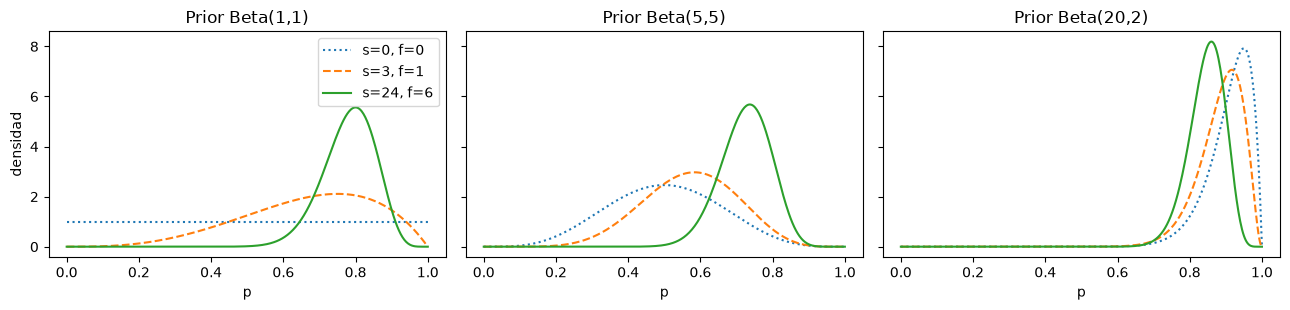

In [4]:
# Visualización de la actualización Beta: un prior y la posterior tras algunos datos
x = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (a0, b0) in zip(axes, [(1, 1), (5, 5), (20, 2)]):
    for s, f, ls in [(0, 0, ":"), (3, 1, "--"), (24, 6, "-")]:
        ax.plot(x, stats.beta.pdf(x, a0 + s, b0 + f), ls,
                label=f"s={s}, f={f}")
    ax.set_title(f"Prior Beta({a0},{b0})")
    ax.set_xlabel("p")
axes[0].set_ylabel("densidad")
axes[0].legend()
plt.tight_layout(); plt.show()

🔮 **Para discutir**: ¿por qué el prior Beta(20,2) "se resiste" más a los datos que Beta(1,1)? ¿Cuántos datos hacen falta para que el prior deje de importar?

## 3. Modelo base corregido

Cambios respecto a la versión anterior:

- El prior se define con `alpha0` y `beta0`; la creencia actual es una **propiedad** (`belief`), separada del prior.
- La regla de decisión es configurable (`decision`): probabilística (como antes), "buscar siempre" o por utilidad esperada (§6).
- Se usa `DataCollector`, de modo que la creencia se registra **en todos los pasos**, aunque el agente no busque. En la versión anterior las curvas tenían longitudes distintas y el eje x no correspondía a pasos.
- El modelo recibe una semilla (`rng`) para reproducibilidad.

In [ ]:
class BayesianAgent(Agent):
    # Agente que aprende la probabilidad de éxito con un modelo Beta-Bernoulli.

    def __init__(self, model, alpha0=1.0, beta0=1.0, decision="probabilistic",
                 reward=1.0, cost=0.0):
        super().__init__(model)
        self.alpha0, self.beta0 = alpha0, beta0   # prior Beta(alpha0, beta0)
        self.successes = 0.0
        self.failures = 0.0
        self.attempts = 0
        self.decision = decision
        self.reward, self.cost = reward, cost

    # --- creencias -------------------------------------------------------
    @property
    def alpha(self):
        return self.alpha0 + self.successes

    @property
    def beta(self):
        return self.beta0 + self.failures

    @property
    def belief(self):
        # Media posterior de p
        return self.alpha / (self.alpha + self.beta)

    # --- decisión --------------------------------------------------------
    def wants_to_search(self):
        options = {
            "probabilistic": self.random.random() < self.belief,
            "always": True,
            # buscar solo si la ganancia esperada supera el costo
            "utility": self.belief * self.reward > self.cost,
        }
        if self.decision not in options:
            raise ValueError(self.decision)
        return options[self.decision]

    # --- aprendizaje -----------------------------------------------------
    def observe(self, success):
        event = self.successes if success else self.failures
        event += 1

    def step(self):
        if self.wants_to_search():
            self.attempts += 1
            self.observe(self.model.search_outcome())


class SimpleBayesModel(Model):
    def __init__(self, n_agents=5, resource_prob=0.8, alpha0=1.0, beta0=1.0,
                 decision="probabilistic", reward=1.0, cost=0.0, rng=None):
        super().__init__(rng=rng)
        self.resource_prob = resource_prob
        BayesianAgent.create_agents(self, n_agents, alpha0=alpha0, beta0=beta0,
                                    decision=decision, reward=reward, cost=cost)
        self.datacollector = DataCollector(
            model_reporters={
                "MeanBelief": lambda m: np.mean([a.belief for a in m.agents]) if len(m.agents) else np.nan,
                "TrueP": "resource_prob",
            },
            agent_reporters={"Belief": "belief", "Alpha":    "alpha",
                             "Beta":   "beta",   "Attempts": "attempts"},
        )
        self.datacollector.collect(self)

    def search_outcome(self):
        # Resultado de una búsqueda: True con probabilidad resource_prob
        return self.random.random() < self.resource_prob

    def step(self):
        self.agents.shuffle_do("step")
        self.datacollector.collect(self)


def run(model_cls=SimpleBayesModel, steps=100, **kwargs):
    model = model_cls(**kwargs)
    for _ in range(steps):
        model.step()
    return model

In [6]:
def plot_beliefs(model, max_lines=10, ax=None):
    # Trayectorias individuales (hasta max_lines agentes) y valor real de p
    df = model.datacollector.get_agent_vars_dataframe()["Belief"].unstack()
    ax = ax or plt.gca()
    for col in list(df.columns)[:max_lines]:
        ax.plot(df.index, df[col], lw=1, alpha=0.8)
    ax.axhline(model.resource_prob, color="k", ls="--", label="p real")
    ax.set_xlabel("Paso"); ax.set_ylabel("Creencia (media posterior)")
    ax.legend()


def plot_population(model, ax=None, label=None):
    # Media poblacional con banda del 5 % al 95 % (útil con muchos agentes)
    df = model.datacollector.get_agent_vars_dataframe()["Belief"].unstack()
    ax = ax or plt.gca()
    line, = ax.plot(df.index, df.mean(axis=1), label=label)
    ax.fill_between(df.index, df.quantile(0.05, axis=1), df.quantile(0.95, axis=1),
                    color=line.get_color(), alpha=0.2)
    ax.set_xlabel("Paso"); ax.set_ylabel("Creencia")

### Experimento 3.1: 5 agentes durante 100 pasos

🔮 **Predicción**: con $p=0.8$ y prior Beta(1,1), ¿todos los agentes llegarán a la misma creencia? ¿Más o menos en qué paso?

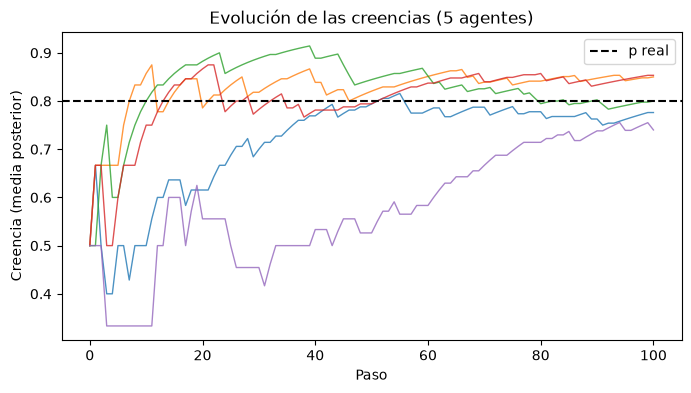

In [7]:
model = run(steps=100, n_agents=5, resource_prob=0.8, rng=SEED)
plt.figure(figsize=(8, 4))
plot_beliefs(model)
plt.title("Evolución de las creencias (5 agentes)")
plt.show()

### Experimento 3.2: el prior sí importa

🔮 **Predicción**: ordena los tres priors según qué tan rápido se acercan a $p=0.8$.

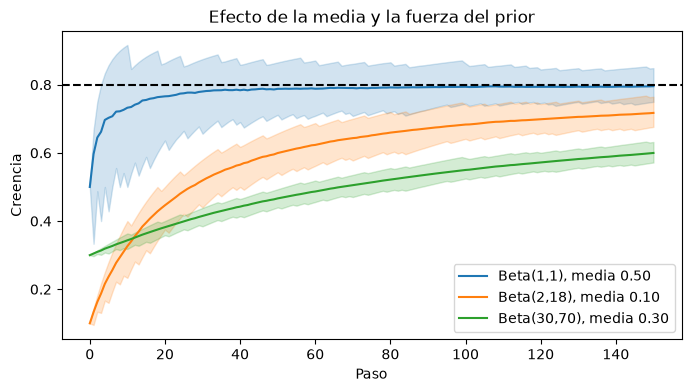

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for a0, b0 in [(1, 1), (2, 18), (30, 70)]:
    m = run(steps=150, n_agents=100, resource_prob=0.8, alpha0=a0, beta0=b0,
            decision="always", rng=SEED)
    plot_population(m, ax=ax, label=f"Beta({a0},{b0}), media {a0/(a0+b0):.2f}")
ax.axhline(0.8, color="k", ls="--")
ax.legend()
ax.set_title("Efecto de la media y la fuerza del prior")
plt.show()

### Experimento 3.3: distintos valores de `resource_prob`

🔮 **Predicción**: con la regla probabilística (buscar con probabilidad igual a la creencia), ¿qué pasa con el número de búsquedas cuando $p$ es bajo?

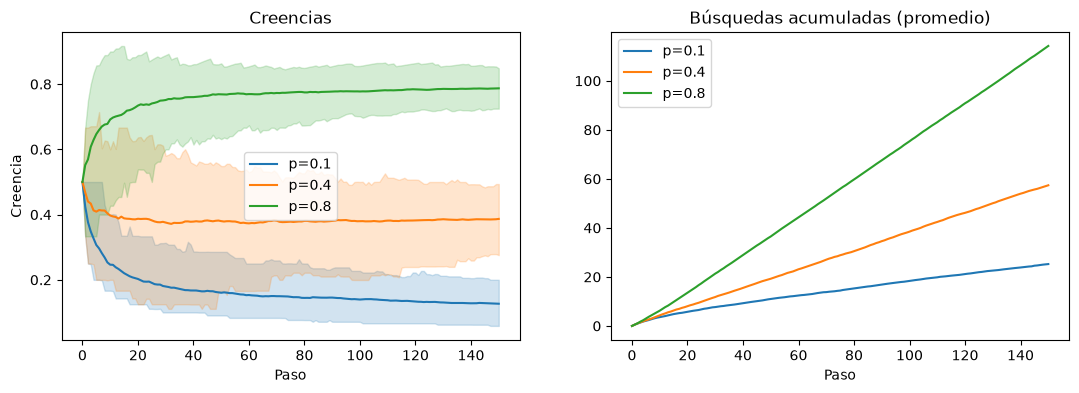

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for p in [0.1, 0.4, 0.8]:
    m = run(steps=150, n_agents=100, resource_prob=p, rng=SEED)
    plot_population(m, ax=axes[0], label=f"p={p}")
    attempts = m.datacollector.get_agent_vars_dataframe()["Attempts"].unstack().mean(axis=1)
    axes[1].plot(attempts.index, attempts, label=f"p={p}")
axes[0].set_title("Creencias"); axes[0].legend()
axes[1].set_title("Búsquedas acumuladas (promedio)")
axes[1].set_xlabel("Paso"); axes[1].legend()
plt.show()

**Observación clave**: cuando la creencia es baja el agente busca poco y, por lo tanto, **recibe menos evidencia**. Aprender requiere actuar. Este es el dilema **exploración–explotación**, que retomamos en §5 y §7.

## 4. Más allá de la media: incertidumbre y convergencia

### 4.1 La posterior completa

La media posterior es solo un resumen. La distribución Beta completa indica **cuán seguro** está el agente.

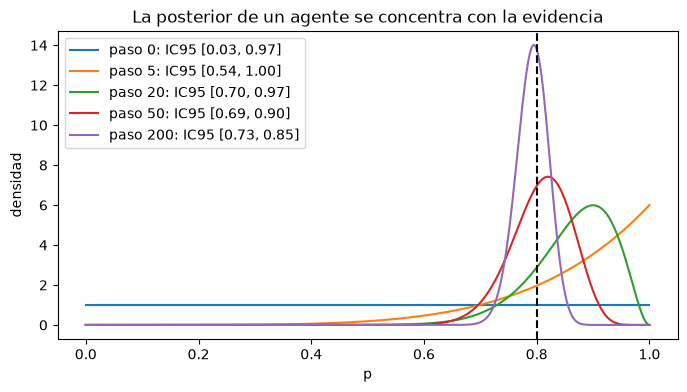

In [10]:
model = run(steps=200, n_agents=1, resource_prob=0.8, decision="always", rng=SEED)
dfa = model.datacollector.get_agent_vars_dataframe().xs(
    next(iter(model.agents)).unique_id, level="AgentID")
x = np.linspace(0, 1, 400)
plt.figure(figsize=(8, 4))
for t in [0, 5, 20, 50, 200]:
    a, b = dfa.loc[t, "Alpha"], dfa.loc[t, "Beta"]
    lo, hi = stats.beta.ppf([0.025, 0.975], a, b)
    plt.plot(x, stats.beta.pdf(x, a, b), label=f"paso {t}: IC95 [{lo:.2f}, {hi:.2f}]")
plt.axvline(0.8, color="k", ls="--")
plt.xlabel("p"); plt.ylabel("densidad"); plt.legend()
plt.title("La posterior de un agente se concentra con la evidencia")
plt.show()

### 4.2 ¿Qué tan rápido converge?

🔮 **Predicción**: si un agente hace 4 veces más búsquedas, ¿por cuánto se reduce su error típico?

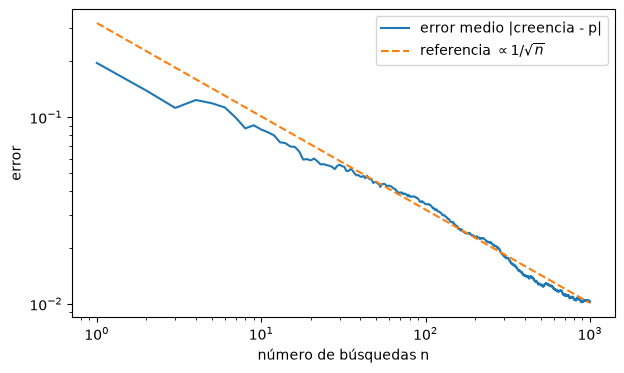

In [11]:
p = 0.8
m = run(steps=1000, n_agents=200, resource_prob=p, decision="always", rng=SEED)
beliefs = m.datacollector.get_agent_vars_dataframe()["Belief"].unstack()
err = (beliefs - p).abs().mean(axis=1).iloc[1:]
n = err.index.values
plt.figure(figsize=(7, 4))
plt.loglog(n, err, label="error medio |creencia - p|")
plt.loglog(n, np.sqrt(2 / np.pi) * np.sqrt(p * (1 - p) / n), "--",
           label=r"referencia $\propto 1/\sqrt{n}$")
plt.xlabel("número de búsquedas n"); plt.ylabel("error")
plt.legend(); plt.show()

El error decae como $1/\sqrt{n}$: para reducirlo a la mitad hacen falta **cuatro veces** más datos.

## 5. La trampa del pesimista: priors heterogéneos

Ahora los agentes deciden por **utilidad esperada**: buscan solo si

$$\hat p \cdot \text{recompensa} > \text{costo}.$$

Mezclamos agentes optimistas, neutrales y pesimistas en un entorno **bueno** ($p=0.8$, recompensa 1, costo 0.3).

🔮 **Predicción**: ¿todos terminan descubriendo que el entorno es bueno?

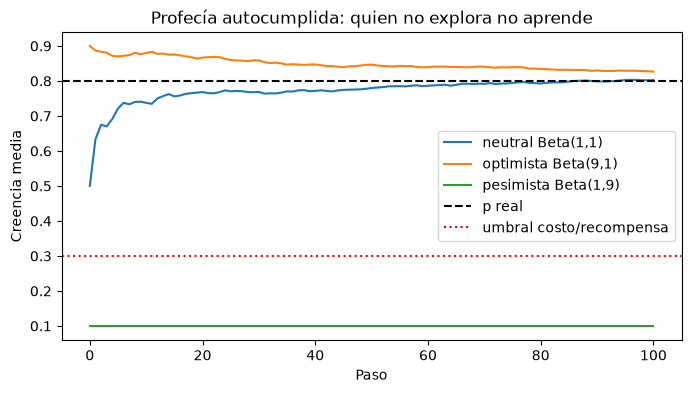

In [12]:
class MixedPriorModel(SimpleBayesModel):
    def __init__(self, n_each=20, resource_prob=0.8, reward=1.0, cost=0.3, rng=None):
        super().__init__(n_agents=0, resource_prob=resource_prob, rng=rng)
        self.groups = {"optimista Beta(9,1)": (9, 1),
                       "neutral Beta(1,1)": (1, 1),
                       "pesimista Beta(1,9)": (1, 9)}
        for name, (a0, b0) in self.groups.items():
            for ag in BayesianAgent.create_agents(self, n_each, alpha0=a0, beta0=b0,
                                                  decision="utility",
                                                  reward=reward, cost=cost):
                ag.group = name
        self.datacollector = DataCollector(
            agent_reporters={"Belief": "belief", "Group": "group"})
        self.datacollector.collect(self)

m = run(MixedPriorModel, steps=100, rng=SEED)
df = m.datacollector.get_agent_vars_dataframe().reset_index()
plt.figure(figsize=(8, 4))
for g, d in df.groupby("Group"):
    s = d.groupby("Step")["Belief"].mean()
    plt.plot(s.index, s, label=g)
plt.axhline(0.8, color="k", ls="--", label="p real")
plt.axhline(0.3, color="r", ls=":", label="umbral costo/recompensa")
plt.xlabel("Paso"); plt.ylabel("Creencia media"); plt.legend()
plt.title("Profecía autocumplida: quien no explora no aprende")
plt.show()

Los pesimistas nunca superan el umbral, nunca buscan y nunca corrigen su creencia. Una **decisión puramente codiciosa** (explotar la creencia actual) puede bloquear el aprendizaje. Las estrategias de §7 resuelven esto.

## 6. Decisión por utilidad esperada

🔮 **Predicción**: con recompensa 1 y costo 0.45, ¿qué fracción de agentes neutrales seguirá buscando a largo plazo si $p=0.40$? ¿Y si $p=0.55$? (Ojo: el prior Beta(1,1) tiene media 0.5, apenas por encima del umbral.)

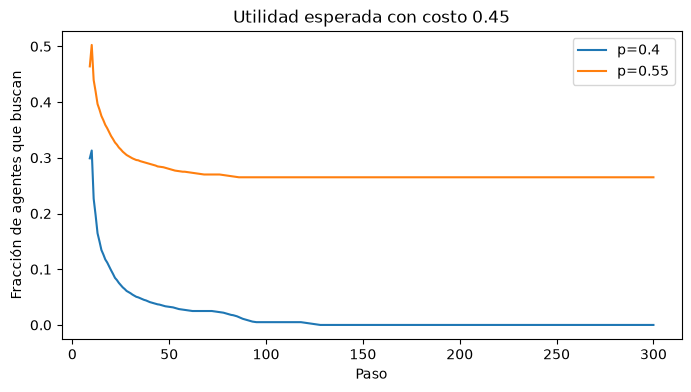

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
for p in [0.40, 0.55]:
    m = run(steps=300, n_agents=200, resource_prob=p, decision="utility",
            reward=1.0, cost=0.45, rng=SEED)
    att = m.datacollector.get_agent_vars_dataframe()["Attempts"].unstack()
    active = (att.diff(axis=0) > 0).mean(axis=1)
    ax.plot(active.index, active.rolling(10).mean(), label=f"p={p}")
ax.set_xlabel("Paso"); ax.set_ylabel("Fracción de agentes que buscan")
ax.legend(); ax.set_title("Utilidad esperada con costo 0.45")
plt.show()

Con $p=0.40$ todos abandonan, como debe ser. Con $p=0.55$ el entorno sí es rentable, pero una racha inicial de mala suerte basta para que una parte de los agentes abandone **para siempre**: al dejar de buscar, ya no reciben evidencia que los saque del error. (Prueba también costo 0.5: con prior de media exactamente 0.5 y desigualdad estricta, ¡nadie busca nunca!) Discute qué ocurre con agentes que abandonan prematuramente en un entorno que sí era rentable.

## 7. Bandido multibrazo espacial

Hasta ahora el entorno era homogéneo: todos aprendían la misma constante y la posición era irrelevante. Ahora la grilla tiene **cuatro regiones** (cuadrantes) con probabilidades distintas y desconocidas. Cada agente:

1. busca en la región donde está y actualiza la Beta **de esa región**;
2. elige una región objetivo según su **estrategia**;
3. si el objetivo es otra región, **se mueve una celda** hacia ella (desplazarse cuesta tiempo).

Estrategias comparadas:

| Estrategia | Regla |
|---|---|
| `greedy` | región con mayor media posterior |
| `epsilon` | como greedy, pero con probabilidad ε elige al azar |
| `ucb` | media + bono de exploración $c\sqrt{\ln t / n_r}$ |
| `thompson` | muestrea $\tilde p_r\sim\text{Beta}(\alpha_r,\beta_r)$ y elige el mayor |
| `qlearning` | Q-learning de un solo estado con ε-greedy (§15) |

El desempeño se mide con el **regret** acumulado: cuánto se pierde, en promedio, por no estar en la mejor región.

In [14]:
REGION_P = [0.2, 0.4, 0.6, 0.85]   # probabilidad real en cada cuadrante


def argmax_random(values, rng):
    # argmax que rompe empates al azar (evita que todos elijan siempre la región 0)
    values = np.asarray(values)
    return int(rng.choice(np.flatnonzero(values == values.max())))


class ForagerAgent(CellAgent):
    def __init__(self, model, cell, strategy="thompson", epsilon=0.1, ucb_c=1.0,
                 social_weight=0.0, liar=False, alpha0=1.0, beta0=1.0,
                 q_alpha=0.1, q_init=1.0):
        super().__init__(model)
        self.cell = cell
        self.strategy = strategy
        self.epsilon, self.ucb_c = epsilon, ucb_c
        self.social_weight, self.liar = social_weight, liar
        k = len(model.region_p)
        self.a = np.full(k, alpha0)   # parámetros Beta por región
        self.b = np.full(k, beta0)
        self.n = np.zeros(k)          # búsquedas por región
        # Q-learning (un solo estado): un valor por región, con inicialización optimista
        self.Q = np.full(k, q_init)
        self.q_alpha = q_alpha
        self.target = self.random.randrange(k)
        self.last_obs = None
        self.regret = 0.0
        self.found = 0

    @property
    def region(self):
        return self.model.region_of(self.cell)

    def choose_target(self):
        r = self.region
        k = len(self.a)
        means = self.a / (self.a + self.b)
        if self.strategy == "greedy":
            return argmax_random(means, self.model.rng)
        if self.strategy == "epsilon":
            return self.random.randrange(k) if self.random.random() < self.epsilon \
                else argmax_random(means, self.model.rng)
        if self.strategy == "ucb":
            t = self.n.sum() + 1
            bonus = self.ucb_c * np.sqrt(np.log(t) / (self.n + 1e-9))
            return argmax_random(means + bonus, self.model.rng)
        if self.strategy == "thompson":
            samples = self.model.rng.beta(self.a, self.b)
            return argmax_random(samples, self.model.rng)
        if self.strategy == "qlearning":
            return self.random.randrange(k) if self.random.random() < self.epsilon \
                else argmax_random(self.Q, self.model.rng)
        raise ValueError(self.strategy)

    def move_towards(self, region):
        tx, ty = self.model.region_center(region)
        dist = lambda c: max(abs(c.coordinate[0] - tx), abs(c.coordinate[1] - ty))
        self.cell = min(self.cell.neighborhood.cells, key=dist)

    def step(self):
        r = self.region
        success = self.model.random.random() < self.model.region_p[r]
        self.found += success
        self.a[r] += success
        self.b[r] += 1 - success
        self.n[r] += 1
        self.regret += max(self.model.region_p) - self.model.region_p[r]
        self.last_obs = (r, (not success) if self.liar else success)

        # aprendizaje social: incorporar observaciones de vecinos con peso w
        if self.social_weight > 0:
            for other in self.cell.neighborhood.agents:
                if other is not self and other.last_obs is not None:
                    rr, ok = other.last_obs
                    self.a[rr] += self.social_weight * ok
                    self.b[rr] += self.social_weight * (1 - ok)

        if self.strategy == "qlearning":
            # actualización con tasa de aprendizaje constante: Q <- Q + α (recompensa - Q)
            self.Q[r] += self.q_alpha * (success - self.Q[r])

        self.target = self.choose_target()
        if self.target != r:
            self.move_towards(self.target)
        else:
            # deambula dentro de su región
            same = [c for c in self.cell.neighborhood.cells
                    if self.model.region_of(c) == r]
            if same:
                self.cell = self.random.choice(same)


class ForagingModel(Model):
    def __init__(self, n_agents=20, width=12, height=12, strategy="thompson",
                 region_p=None, social_weight=0.0, liar_fraction=0.0, rng=None,
                 **agent_kwargs):
        super().__init__(rng=rng)
        self.width, self.height = width, height
        self.region_p = list(region_p or REGION_P)
        self.grid = OrthogonalMooreGrid((width, height), torus=False, random=self.random)
        cells = self.random.choices(self.grid.all_cells.cells, k=n_agents)
        for i, c in enumerate(cells):
            ForagerAgent(self, c, strategy=strategy, social_weight=social_weight,
                         liar=(i < liar_fraction * n_agents), **agent_kwargs)
        self.datacollector = DataCollector(
            model_reporters={
                "MeanRegret": lambda m: np.mean([a.regret for a in m.agents]),
                "InBest": lambda m: np.mean([a.region == int(np.argmax(m.region_p))
                                             for a in m.agents]),
            })
        self.datacollector.collect(self)

    def region_of(self, cell):
        x, y = cell.coordinate
        return int(x >= self.width / 2) + 2 * int(y >= self.height / 2)

    def region_center(self, r):
        cx = self.width * (0.75 if r % 2 else 0.25)
        cy = self.height * (0.75 if r >= 2 else 0.25)
        return cx, cy

    def step(self):
        self.agents.shuffle_do("step")
        self.datacollector.collect(self)


def compare(configs, steps=200, seeds=(1, 2, 3), **common):
    # Ejecuta varias configuraciones con varias semillas y devuelve el regret medio
    out = {}
    for name, kw in configs.items():
        runs = [run(ForagingModel, steps=steps, rng=s, **common, **kw)
                .datacollector.get_model_vars_dataframe() for s in seeds]
        out[name] = pd.concat(runs).groupby(level=0).mean()
    return out

🔮 **Predicción**: ordena `greedy`, `epsilon`, `ucb` y `thompson` de menor a mayor regret acumulado tras 200 pasos.

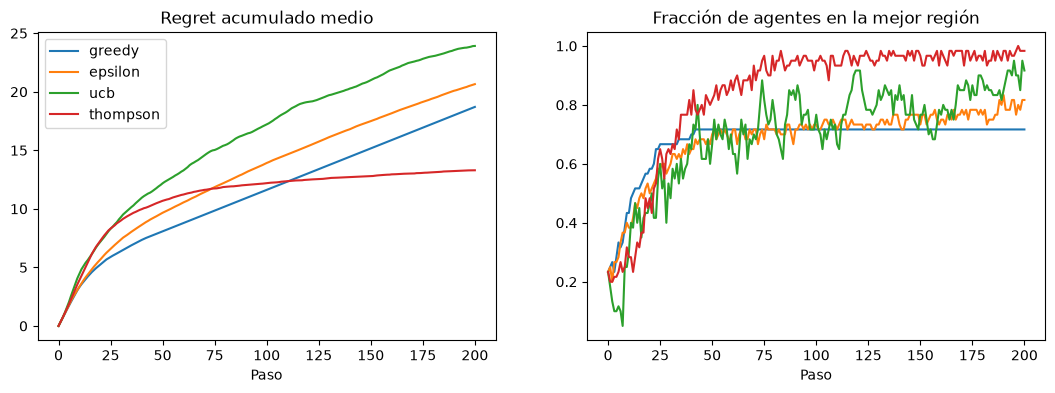

In [15]:
res = compare({s: {"strategy": s} for s in ["greedy", "epsilon", "ucb", "thompson"]})
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, d in res.items():
    axes[0].plot(d.index, d["MeanRegret"], label=name)
    axes[1].plot(d.index, d["InBest"], label=name)
axes[0].set_title("Regret acumulado medio"); axes[0].set_xlabel("Paso")
axes[1].set_title("Fracción de agentes en la mejor región"); axes[1].set_xlabel("Paso")
axes[0].legend(); plt.show()

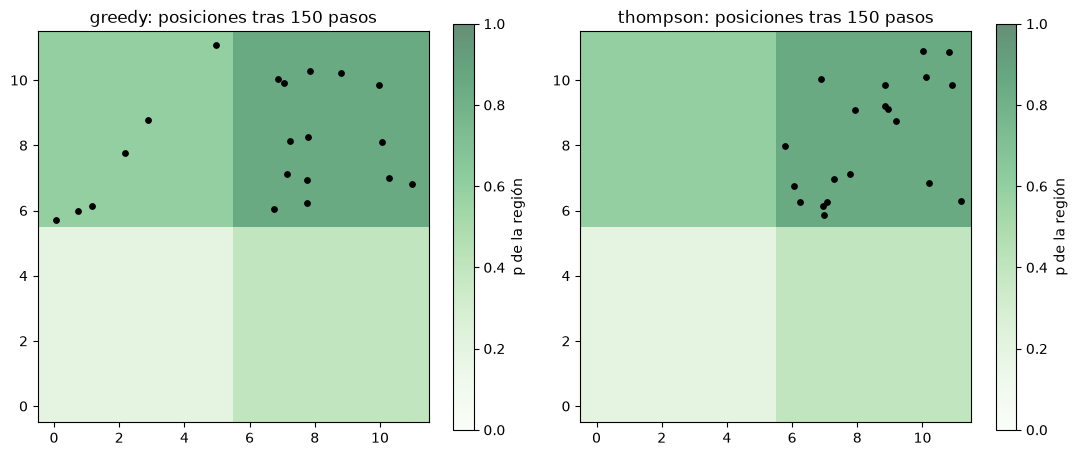

In [16]:
def plot_positions(model, title=""):
    # Fondo con la probabilidad de cada región y posición de los agentes
    W, H = model.width, model.height
    bg = np.array([[model.region_p[int(x >= W / 2) + 2 * int(y >= H / 2)]
                    for x in range(W)] for y in range(H)])
    im = plt.imshow(bg, origin="lower", cmap="Greens", vmin=0, vmax=1, alpha=0.6)
    xy = np.array([a.cell.coordinate for a in model.agents])
    jitter = model.rng.uniform(-0.3, 0.3, xy.shape)
    plt.scatter(xy[:, 0] + jitter[:, 0], xy[:, 1] + jitter[:, 1], c="k", s=15)
    plt.title(title); plt.colorbar(im, label="p de la región")

plt.figure(figsize=(11, 4.5))
for i, s in enumerate(["greedy", "thompson"]):
    plt.subplot(1, 2, i + 1)
    plot_positions(run(ForagingModel, steps=150, strategy=s, rng=SEED),
                   f"{s}: posiciones tras 150 pasos")
plt.tight_layout(); plt.show()

**Para discutir**: el agente `greedy` se queda en la primera región que le parece "suficientemente buena". El muestreo de Thompson explora en proporción a su incertidumbre: es la extensión natural del agente bayesiano de §3.

## 8. Aprendizaje social

Cada agente comparte su última observación (región, éxito) con los vecinos de su celda y de las celdas adyacentes, que la incorporan con un peso de confianza $w$. Agregamos también agentes **mentirosos** que reportan el resultado contrario.

🔮 **Predicción**: ¿compartir información siempre ayuda? ¿Qué fracción de mentirosos la vuelve perjudicial?

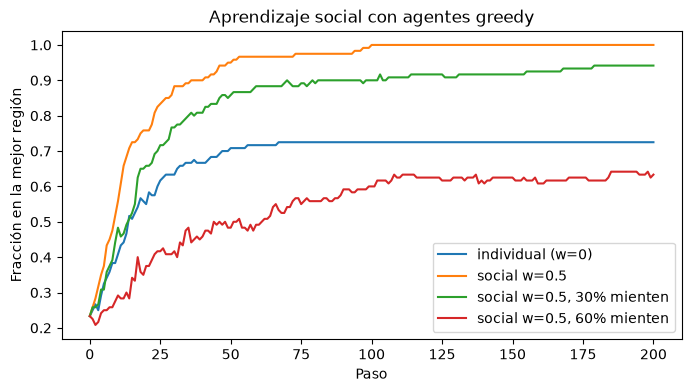

In [17]:
configs = {
    "individual (w=0)": {"social_weight": 0.0},
    "social w=0.5": {"social_weight": 0.5},
    "social w=0.5, 30% mienten": {"social_weight": 0.5, "liar_fraction": 0.3},
    "social w=0.5, 60% mienten": {"social_weight": 0.5, "liar_fraction": 0.6},
}
res = compare(configs, strategy="greedy", n_agents=40)
plt.figure(figsize=(8, 4))
for name, d in res.items():
    plt.plot(d.index, d["InBest"], label=name)
plt.xlabel("Paso"); plt.ylabel("Fracción en la mejor región")
plt.title("Aprendizaje social con agentes greedy"); plt.legend(); plt.show()

Con agentes `greedy`, la información de los vecinos funciona como **exploración prestada**. Si muchos reportan en falso, el grupo puede converger a una región equivocada: es una **cascada de información**. Ejercicio: haz que la confianza $w$ de cada vecino se ajuste según qué tan bien predijeron sus reportes las observaciones propias.

## 9. Entorno que cambia: olvido exponencial

En el paso 150 el recurso se agota: $p$ pasa de 0.8 a 0.2. Un agente bayesiano "puro" acumula toda la historia y reacciona lentamente. Un agente con **factor de olvido** $\gamma<1$ descuenta los conteos viejos:

$$ s \leftarrow \gamma s + \mathbb{1}[\text{éxito}], \qquad f \leftarrow \gamma f + \mathbb{1}[\text{fracaso}]. $$

🔮 **Predicción**: ¿qué agente estima mejor $p$ **antes** del cambio? ¿Y después?

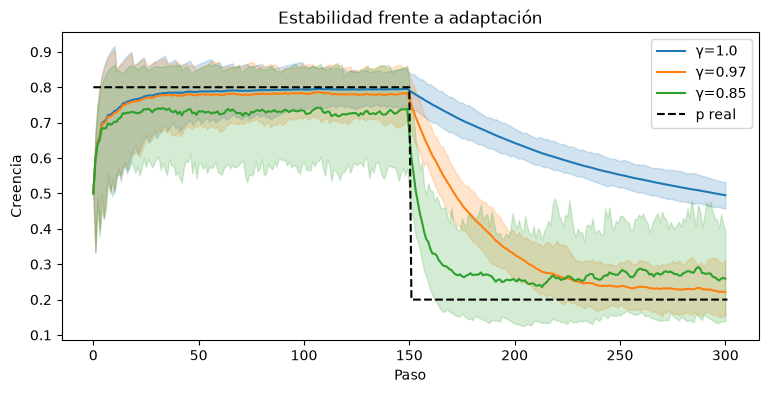

In [18]:
class ForgettingAgent(BayesianAgent):
    def __init__(self, model, gamma=1.0, **kw):
        super().__init__(model, **kw)
        self.gamma = gamma

    def observe(self, success):
        self.successes = self.gamma * self.successes + success
        self.failures = self.gamma * self.failures + (1 - success)


class ChangingModel(SimpleBayesModel):
    def __init__(self, n_agents=100, gamma=1.0, change_step=150,
                 p_before=0.8, p_after=0.2, rng=None):
        super().__init__(n_agents=0, resource_prob=p_before, rng=rng)
        self.change_step, self.p_after = change_step, p_after
        ForgettingAgent.create_agents(self, n_agents, gamma=gamma, decision="always")
        self.datacollector.collect(self)

    def step(self):
        if self.steps == self.change_step:
            self.resource_prob = self.p_after
        super().step()

plt.figure(figsize=(9, 4))
for g in [1.0, 0.97, 0.85]:
    m = run(ChangingModel, steps=300, gamma=g, rng=SEED)
    plot_population(m, label=f"γ={g}")
d = m.datacollector.get_model_vars_dataframe()
plt.plot(d.index, d["TrueP"], "k--", label="p real")
plt.legend(); plt.title("Estabilidad frente a adaptación")
plt.show()

Un $\gamma$ pequeño se adapta rápido, pero la estimación es más ruidosa (memoria efectiva $\approx 1/(1-\gamma)$ observaciones). Es el compromiso entre **estabilidad y adaptación**.

## 10. Energía, supervivencia y selección de creencias

Cada agente tiene energía. Buscar cuesta `cost`, encontrar el recurso da `reward` y vivir cuesta `metabolism` por paso. Si la energía llega a 0 el agente muere; si supera un umbral se reproduce y su descendiente **hereda la media de su prior** con una pequeña mutación. El éxito disminuye cuando la población crece (capacidad de carga).

🔮 **Predicción**: en un entorno rentable, ¿qué priors sobreviven? ¿Y en uno que no es rentable?

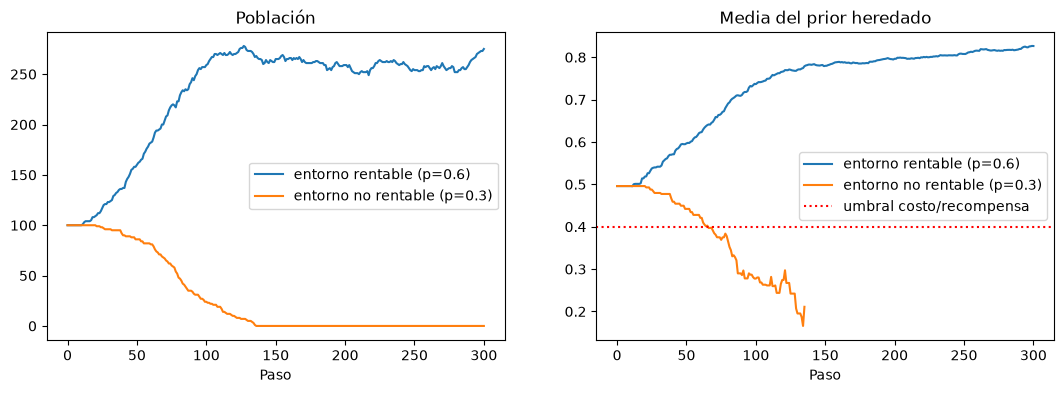

In [19]:
class EvoAgent(BayesianAgent):
    def __init__(self, model, prior_mean=0.5, strength=4.0, energy=5.0):
        m = min(max(prior_mean, 0.01), 0.99)
        super().__init__(model, alpha0=m * strength, beta0=(1 - m) * strength,
                         decision="utility", reward=model.reward, cost=model.cost)
        self.prior_mean, self.strength, self.energy = m, strength, energy

    def step(self):
        if self.wants_to_search():
            self.energy -= self.cost
            ok = self.model.search_outcome()
            self.observe(ok)
            self.energy += self.reward * ok
        self.energy -= self.model.metabolism
        if self.energy <= 0:
            self.remove()
        elif self.energy > 10:
            self.energy /= 2
            EvoAgent(self.model,
                     prior_mean=self.prior_mean + self.model.rng.normal(0, 0.05),
                     strength=self.strength, energy=self.energy)


class EvoModel(Model):
    def __init__(self, n_agents=100, resource_prob=0.6, reward=1.0, cost=0.4,
                 metabolism=0.05, capacity=200, rng=None):
        super().__init__(rng=rng)
        self.base_p, self.reward, self.cost = resource_prob, reward, cost
        self.metabolism, self.capacity = metabolism, capacity
        for _ in range(n_agents):
            EvoAgent(self, prior_mean=self.random.random(),
                     energy=self.random.uniform(3, 7))
        self.datacollector = DataCollector(model_reporters={
            "N": lambda m: len(m.agents),
            "MeanPrior": lambda m: np.mean([a.prior_mean for a in m.agents]) if len(m.agents) else np.nan,
        })
        self.datacollector.collect(self)

    def search_outcome(self):
        p = self.base_p * min(1.0, self.capacity / max(len(self.agents), 1))
        return self.random.random() < p

    def step(self):
        if len(self.agents):
            self.agents.shuffle_do("step")
        self.datacollector.collect(self)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for p, lab in [(0.6, "entorno rentable (p=0.6)"), (0.3, "entorno no rentable (p=0.3)")]:
    d = run(EvoModel, steps=300, resource_prob=p, rng=SEED).datacollector.get_model_vars_dataframe()
    axes[0].plot(d.index, d["N"], label=lab)
    axes[1].plot(d.index, d["MeanPrior"], label=lab)
axes[0].set_title("Población"); axes[1].set_title("Media del prior heredado")
axes[1].axhline(0.4, color="r", ls=":", label="umbral costo/recompensa")
for ax in axes: ax.set_xlabel("Paso"); ax.legend()
plt.show()

En el entorno rentable, los pesimistas extremos nunca buscan y mueren de hambre cuando se les acaba la energía inicial; los que sí buscan aprenden, se reproducen y la media del prior heredado sube. En el entorno no rentable, los **optimistas mueren primero** (gastan energía antes de aprender que no conviene buscar); los pesimistas aguantan más, pero sin otra fuente de energía la población se extingue: ninguna creencia salva a un agente sin alternativas.

**Para discutir**: ¿la evolución produce creencias **verdaderas** o creencias **útiles**? Ejercicio: agrega una fuente segura de energía (por ejemplo, 0.05 por paso cuando el agente no busca) y repite el experimento en el entorno no rentable.

## 11. Estado oculto: filtrado bayesiano

El parche alterna en secreto entre un estado **bueno** ($p=0.8$) y uno **malo** ($p=0.2$). En cada paso cambia de estado con probabilidad $q=0.03$ (cadena de Markov oculta). El agente no ve el estado; solo ve éxitos y fracasos. Mantiene $b_t = P(\text{bueno}\mid\text{observaciones})$ con el algoritmo *forward*:

1. **Predicción**: $\bar b = b_{t-1}(1-q) + (1-b_{t-1})\,q$.
2. **Corrección**: $b_t \propto \bar b\,P(o_t\mid\text{bueno})$, normalizado contra $(1-\bar b)\,P(o_t\mid\text{malo})$.

Esto conecta con la idea de **reconstruir estados no observados**; los filtros de partículas generalizan este procedimiento.

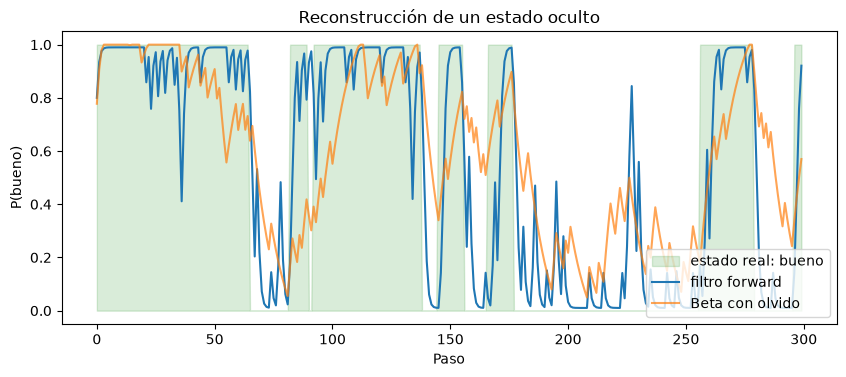

In [20]:
class FilterAgent(Agent):
    def __init__(self, model, q=0.03, p_good=0.8, p_bad=0.2):
        super().__init__(model)
        self.q, self.pg, self.pb = q, p_good, p_bad
        self.b = 0.5

    def step(self):
        ok = self.model.search_outcome()
        prior = self.b * (1 - self.q) + (1 - self.b) * self.q
        lg = self.pg if ok else 1 - self.pg
        lb = self.pb if ok else 1 - self.pb
        self.b = prior * lg / (prior * lg + (1 - prior) * lb)


class HiddenStateModel(Model):
    def __init__(self, q=0.03, rng=None):
        super().__init__(rng=rng)
        self.q, self.good = q, True
        self.filter_agent = FilterAgent(self, q=q)
        self.forget_agent = ForgettingAgent(self, gamma=0.9, decision="always")
        self.datacollector = DataCollector(model_reporters={
            "Bueno": lambda m: float(m.good),
            "Filtro P(bueno)": lambda m: m.filter_agent.b,
            "Olvido γ=0.9 (reescalado)": lambda m: (m.forget_agent.belief - 0.2) / 0.6,
        })

    @property
    def resource_prob(self):
        return 0.8 if self.good else 0.2

    def search_outcome(self):
        return self.random.random() < self.resource_prob

    def step(self):
        if self.random.random() < self.q:
            self.good = not self.good
        self.agents.shuffle_do("step")
        self.datacollector.collect(self)

d = run(HiddenStateModel, steps=300, rng=7).datacollector.get_model_vars_dataframe()
plt.figure(figsize=(10, 3.8))
plt.fill_between(d.index, 0, d["Bueno"], color="g", alpha=0.15, label="estado real: bueno")
plt.plot(d.index, d["Filtro P(bueno)"], label="filtro forward")
plt.plot(d.index, d["Olvido γ=0.9 (reescalado)"].clip(0, 1), alpha=0.7, label="Beta con olvido")
plt.xlabel("Paso"); plt.ylabel("P(bueno)"); plt.legend(loc="lower right")
plt.title("Reconstrucción de un estado oculto"); plt.show()

El filtro usa **conocimiento estructural** (sabe que hay dos estados y cómo cambian) y por eso reacciona más rápido y con menos ruido que el agente que solo olvida. Ejercicio: ¿qué pasa si el agente usa un $q$ distinto del real?

## 12. Inferencia sobre el modelo: ABC por rechazo

Ahora el que infiere es el **modelador**. Observamos solo un dato agregado de una simulación (la fracción de búsquedas exitosas y el número total de búsquedas) generada con un $p$ que **no conocemos**. Para estimarlo:

1. Muestreamos $p$ del prior (uniforme).
2. Simulamos el modelo con ese $p$.
3. Aceptamos $p$ si la simulación produce datos parecidos a los observados.

Los valores aceptados aproximan la posterior $P(p\mid \text{datos})$.

🔮 **Predicción**: ¿la posterior estará centrada en el valor real? ¿Será angosta o ancha?

Datos observados: [0.657 0.178]


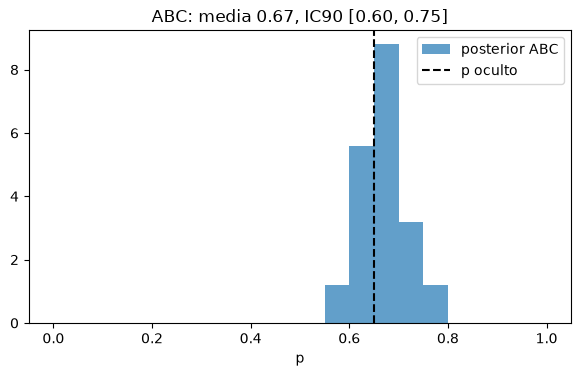

In [21]:
def summary(model):
    s = sum(a.successes for a in model.agents)
    n = sum(a.attempts for a in model.agents)
    return np.array([s / max(n, 1), n / 1000])

P_HIDDEN = 0.65
observed = summary(run(steps=30, n_agents=10, resource_prob=P_HIDDEN, rng=123))
print("Datos observados:", observed.round(3))

rng = np.random.default_rng(SEED)
draws, dists = [], []
for i in range(500):
    p = rng.uniform()
    sim = summary(run(steps=30, n_agents=10, resource_prob=p, rng=int(rng.integers(1e9))))
    draws.append(p); dists.append(np.linalg.norm(sim - observed))
draws, dists = np.array(draws), np.array(dists)
accepted = draws[dists <= np.quantile(dists, 0.1)]

plt.figure(figsize=(7, 3.8))
plt.hist(accepted, bins=20, range=(0, 1), density=True, alpha=0.7, label="posterior ABC")
plt.axvline(P_HIDDEN, color="k", ls="--", label="p oculto")
plt.xlabel("p"); plt.legend()
plt.title(f"ABC: media {accepted.mean():.2f}, IC90 "
          f"[{np.quantile(accepted, .05):.2f}, {np.quantile(accepted, .95):.2f}]")
plt.show()

Compara: en §3 cada **agente** infería $p$ con sus propios datos; aquí el **modelador** infiere un parámetro del modelo con datos agregados, sin acceso a los agentes.

## 13. Análisis de sensibilidad con `batch_run`

¿Qué parámetros influyen más en el error final de las creencias y en el esfuerzo de búsqueda?

In [22]:
results = batch_run(
    SimpleBayesModel,
    parameters={"n_agents": 20, "resource_prob": [0.2, 0.5, 0.8],
                "alpha0": [1, 10], "beta0": [1, 10], "decision": "probabilistic"},
    max_steps=100, data_collection_period=-1,
    display_progress=False, rng=[1, 2, 3],   # tres repeticiones con semillas fijas
)
df = pd.DataFrame(results)
df["Error"] = (df["Belief"] - df["resource_prob"]).abs()
tabla = df.groupby(["resource_prob", "alpha0", "beta0"])[["Error", "Attempts"]].mean().round(3)
tabla

Error  Attempts
resource_prob alpha0 beta0                 
0.2           1      1      0.058    24.700
                     10     0.095    10.167
              10     1      0.130    45.933
                     10     0.099    36.133
0.5           1      1      0.066    47.683
                     10     0.145    23.450
              10     1      0.062    62.350
                     10     0.045    49.750
0.8           1      1      0.048    75.567
                     10     0.175    38.667
              10     1      0.035    82.183
                     10     0.075    66.150

Ejercicio: identifica en la tabla la combinación de prior y $p$ con mayor error y explícala a partir de §3.3 y §5.

## 14. Conexión con agentes basados en conocimiento: Wumpus probabilístico

En la clase de agentes basados en conocimiento, el agente del Wumpus usaba inferencia **lógica**. A veces la lógica no decide: ninguna celda es *segura con certeza*. La probabilidad sí permite elegir la **menos riesgosa**.

Situación clásica (Russell y Norvig): el agente visitó (1,1), (1,2) y (2,1) sin caer; percibe brisa en (1,2) y en (2,1). Cada celda tiene un pozo con probabilidad previa 0.2. Calculamos por enumeración la probabilidad de pozo en las celdas de la frontera.

In [23]:
from itertools import product

def neighbors(c, size=4):
    x, y = c
    return [(x + dx, y + dy) for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]
            if 1 <= x + dx <= size and 1 <= y + dy <= size]

def pit_probabilities(visited, breeze, prior=0.2, size=4):
    # P(pozo) en cada celda de la frontera, por enumeración de configuraciones
    frontier = sorted({n for v in visited for n in neighbors(v, size)} - set(visited))
    weights = {c: 0.0 for c in frontier}
    total = 0.0
    for config in product([0, 1], repeat=len(frontier)):
        pits = {c for c, z in zip(frontier, config) if z}
        consistent = all(any(n in pits for n in neighbors(v, size)) == breeze[v]
                         for v in visited)
        if not consistent:
            continue
        w = np.prod([prior if z else 1 - prior for z in config])
        total += w
        for c in pits:
            weights[c] += w
    return {c: w / total for c, w in weights.items()}

visited = [(1, 1), (1, 2), (2, 1)]
breeze = {(1, 1): False, (1, 2): True, (2, 1): True}
for c, p in pit_probabilities(visited, breeze).items():
    print(f"P(pozo en {c}) = {p:.2f}")

P(pozo en (1, 3)) = 0.31
P(pozo en (2, 2)) = 0.86
P(pozo en (3, 1)) = 0.31


El agente debería evitar (2,2) (≈0.86) y preferir (1,3) o (3,1) (≈0.31). Ejercicio: integra `pit_probabilities` al agente del Wumpus de la clase anterior para que, cuando no haya celdas seguras, elija la de menor riesgo. Haz lo mismo con el Buscaminas simplificado.

## 15. Puente con aprendizaje por refuerzo: Q-learning vs. Thompson

El agente de Q-learning no modela explícitamente la incertidumbre: aprende un **valor** por región con una tasa de aprendizaje constante,

$$Q_r \leftarrow Q_r + \alpha\,(\text{recompensa} - Q_r),$$

y explora con ε-greedy. Es la versión más simple de Q-learning (un solo estado, sin descuento). Empieza con valores optimistas ($Q_r=1$) para animarse a probar todas las regiones.

🔮 **Predicción**: ¿cuál aprende más rápido en el bandido espacial? ¿Por qué?

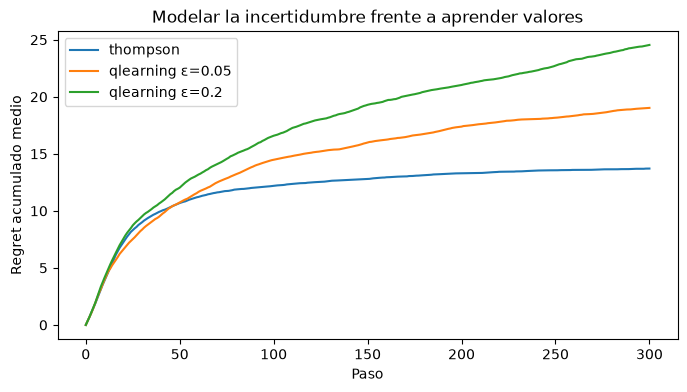

In [24]:
res = compare({"thompson": {"strategy": "thompson"},
               "qlearning ε=0.05": {"strategy": "qlearning", "epsilon": 0.05},
               "qlearning ε=0.2": {"strategy": "qlearning", "epsilon": 0.2}},
              steps=300)
plt.figure(figsize=(8, 4))
for name, d in res.items():
    plt.plot(d.index, d["MeanRegret"], label=name)
plt.xlabel("Paso"); plt.ylabel("Regret acumulado medio")
plt.title("Modelar la incertidumbre frente a aprender valores"); plt.legend(); plt.show()

**Para discutir**: Thompson aprovecha que sabe *cuánto* sabe (la forma de la Beta). Q-learning es más general (sirve para problemas con estados y consecuencias diferidas), pero en este problema explora de forma menos eficiente: con ε fijo sigue explorando al azar para siempre y su regret crece linealmente.

Ejercicios: (a) cambia `q_init` a 0. Sin inicialización optimista, ¿qué región aprende a preferir el agente y por qué? (b) Cambia `q_alpha`. ¿Qué ventaja tiene una tasa constante en el entorno no estacionario de §9? (c) Extiende el agente a Q-learning con estados (región actual) y descuento γ.

## 16. Ejercicios

1. **Fuerza del prior.** En §3.2 encuentra cuántas búsquedas necesita el prior Beta(30,70) para que su creencia esté a menos de 0.05 del valor real. Relaciónalo con $\alpha_0+\beta_0$.
2. **Convergencia.** En §4.2 repite el experimento con $p=0.5$ y $p=0.95$. ¿Cambia la pendiente? ¿Cambia la constante? Explica con $\sqrt{p(1-p)/n}$.
3. **Rescatar al pesimista.** Modifica la regla de decisión de §5 para que los pesimistas exploren de vez en cuando (por ejemplo, Thompson con una sola región). ¿Cuántos pasos tardan en "descubrir" el entorno?
4. **Moverse solo si falla.** En el bandido espacial (§7) crea una estrategia que permanezca en la región actual mientras tenga éxito y se mueva hacia otra región tras un fracaso (*win-stay, lose-shift*). Compárala con Thompson.
5. **Confianza adaptativa.** En §8 haz que el peso $w$ de cada vecino dependa de qué tan bien concuerdan sus reportes con tus propias observaciones. ¿Se neutralizan los mentirosos?
6. **Agotamiento local.** Haz que cada búsqueda exitosa reduzca temporalmente la probabilidad de la región y que esta se regenere poco a poco. ¿Qué estrategia se beneficia del factor de olvido de §9?
7. **Situaciones reales.** Para cada caso, identifica qué es el *recurso*, el *prior*, la *evidencia* y la *decisión*, y qué sección del notebook lo modela mejor:
   - campesinos que deciden adoptar una nueva variedad de semilla observando sus cosechas y las de sus vecinos;
   - pescadores que eligen zonas de pesca con rendimientos que cambian por temporada;
   - usuarios que eligen entre rutas de transporte con tiempos de viaje inciertos.

y ya jugarme para tener mayores posibilidades. Puedes no sostimar que tan rápido está aprendiendo una gente. Hay agentes que aprenden y actualizan sus probabilidades acertadamente en muy pocos intentosEstos intentos se permiten estar quietos porque ya tienen una información lo suficientemente confiable, como hay otras que bajo configuraciones diferentes requieren mucho más esfuerzo e intentos para poder lograr la petición que quieran Todas esas possibilidades andas combinadas las podemos usar para modelar los sistemas que nos interesen.

Muchas ofignias que describimos de comportamiento humano porque digamos están cercanos a nuestra intuición que yo hable en un restaurante que me gusta o de unas relaciones personales o de una estrategia económica o lo que sea ya no estamos familiarizados. But then it's utilizado and functional for those of the no clarity the criteria of decision in comportamiento economic, in comportamiento animal, comportamiento de clima, pero que definimos unas combinaciones apropiadas y se reproduce de manera parecida al sistema que estamos tratando de describir.

Esa es como la película grande. Ya reviste en detalle de cómo lo hacemos exactamente, de cómo lo combinamos, de cómo lo medimos, de cómo lo simulamos. No sé si hay preguntas o inquietudes. Si ustedes más bien preguntan yo sí, vamos a ver Perfecto, ¿no?

La idea de la presentación es que No, digamos okay. no, no, no, no. espacio. Igual notebook lo subes a la plataforma. Pero sí, digamos como que el notebook así para exponerlo. Aquí me funciona no Pero como tú vas a tener 10 minutos, entonces preparas algo chévere, conceptual, bonito, completo, espectacular.

Te faltan dos detalles por lo mejor. Un detalle. Uno que se llama proyectos. Gracias. Nos vemos el viernes siguiente.